In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 100)

df_original = pd.read_csv(r"D:\tasks\Student_Performance.csv")
print('Dataset shape:', df_original.shape)
display(df_original.head())


Dataset shape: (10000, 6)


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


In [2]:
display(df_original.info())
display(df_original.describe(include='all').T)
display(df_original.isna().sum().sort_values(ascending=False).to_frame('Missing Values'))
print('Duplicate rows:', df_original.duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        8428 non-null   str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  7144 non-null   float64
 5   Performance Index                 10000 non-null  int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 468.9 KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hours Studied,10000.0,NaN,NaN,NaN,4.9929,2.589309,1.0,3.0,5.0,7.0,9.0
Previous Scores,10000.0,NaN,NaN,NaN,69.4457,17.343152,40.0,54.0,69.0,85.0,99.0
Extracurricular Activities,8428,2,No,4251,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep Hours,10000.0,NaN,NaN,NaN,6.5306,1.695863,4.0,5.0,7.0,8.0,9.0
Sample Question Papers Practiced,7144.0,NaN,NaN,NaN,4.572788,2.868633,0.0,2.0,5.0,7.0,9.0
Performance Index,10000.0,NaN,NaN,NaN,55.2248,19.212558,10.0,40.0,55.0,71.0,100.0


,Missing Values
Sample Question Papers Practiced,2856
Extracurricular Activities,1572
Previous Scores,0
Hours Studied,0
Sleep Hours,0
Performance Index,0


Duplicate rows: 132


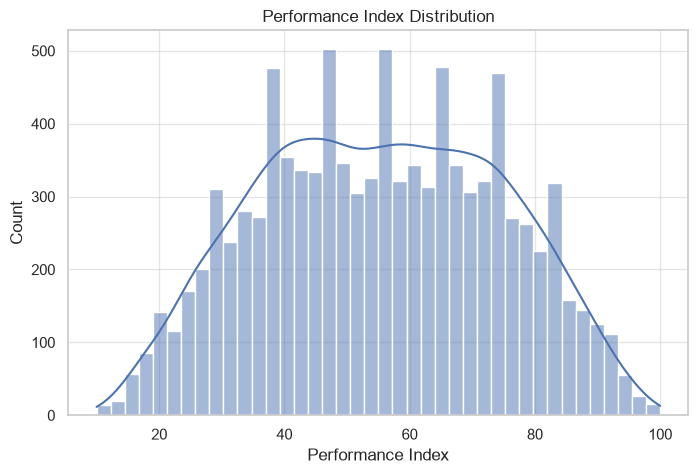

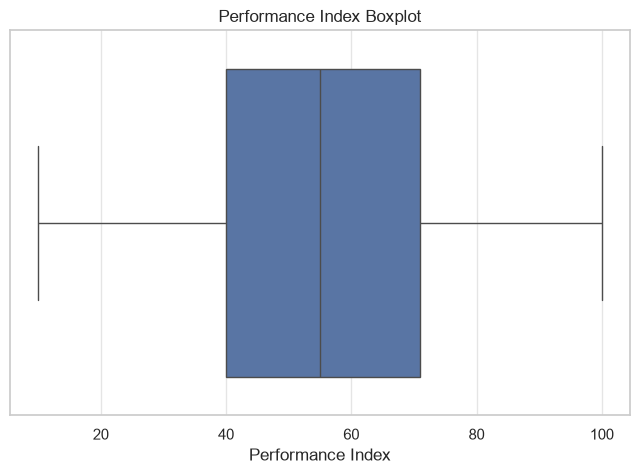

In [3]:
plt.figure(figsize=(8, 5))
sns.histplot(df_original['Performance Index'], bins=40, kde=True)
plt.title('Performance Index Distribution')
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(x=df_original['Performance Index'])
plt.title('Performance Index Boxplot')
plt.show()


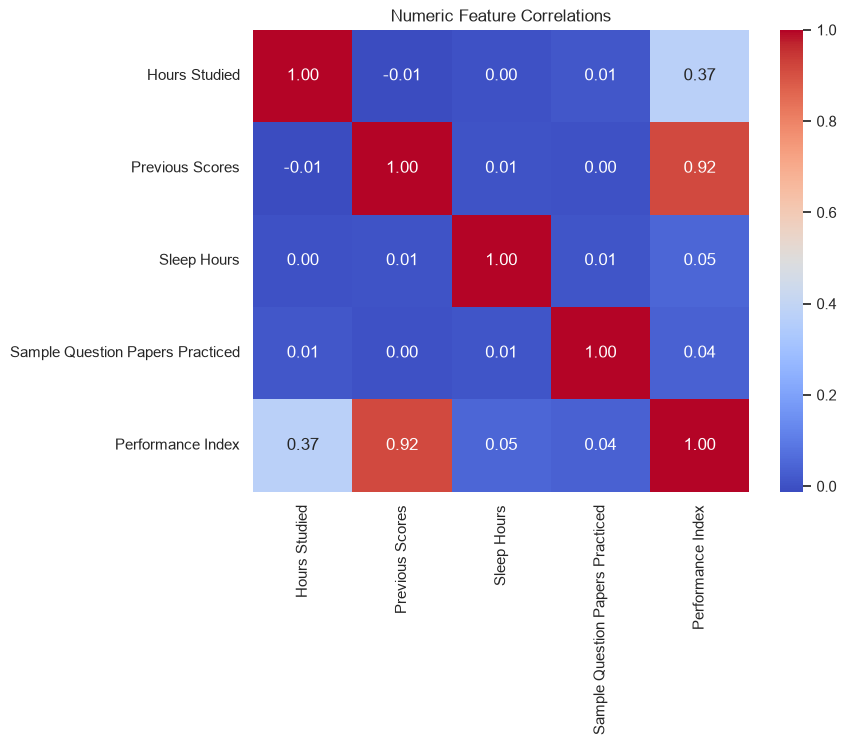

In [4]:
numeric_cols = df_original.select_dtypes(include=np.number).columns
plt.figure(figsize=(8, 6))
sns.heatmap(df_original[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Numeric Feature Correlations')
plt.show()


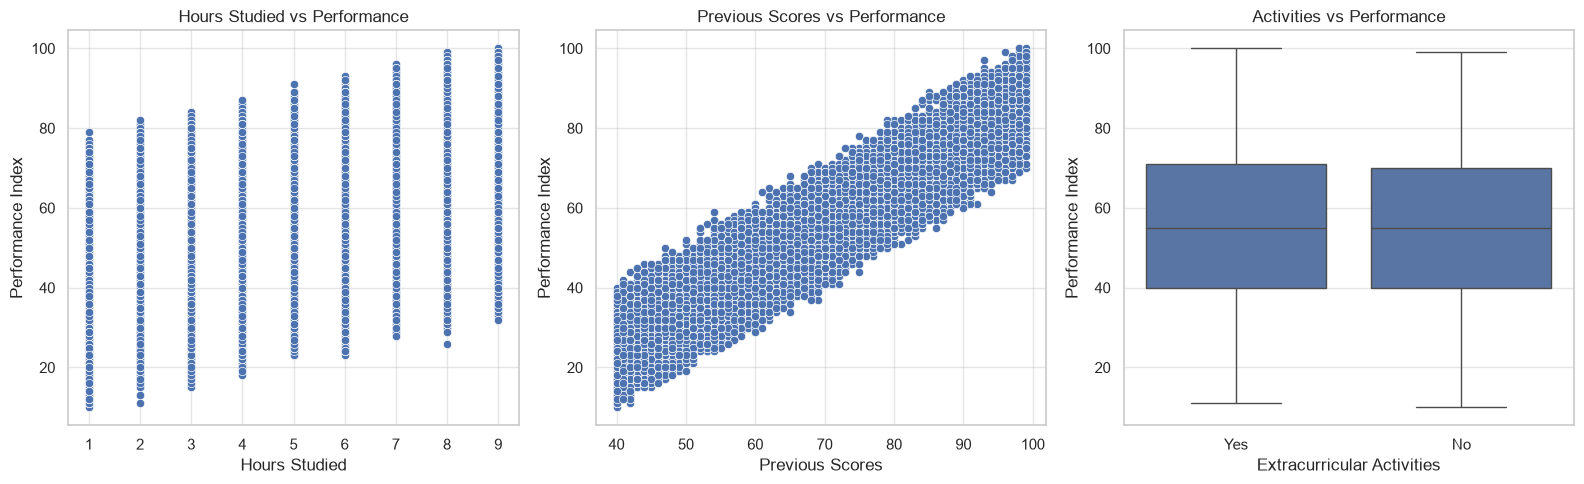

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sns.scatterplot(data=df_original, x='Hours Studied', y='Performance Index', ax=axes[0])
axes[0].set_title('Hours Studied vs Performance')
sns.scatterplot(data=df_original, x='Previous Scores', y='Performance Index', ax=axes[1])
axes[1].set_title('Previous Scores vs Performance')
sns.boxplot(data=df_original, x='Extracurricular Activities', y='Performance Index', ax=axes[2])
axes[2].set_title('Activities vs Performance')
plt.tight_layout()
plt.show()


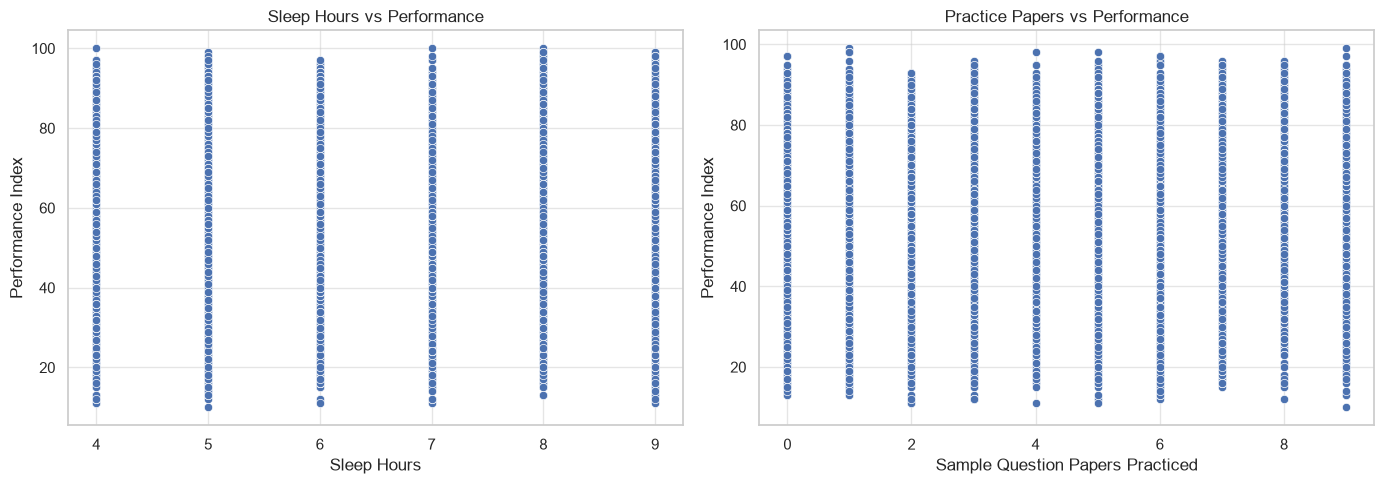

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df_original, x='Sleep Hours', y='Performance Index', ax=axes[0])
axes[0].set_title('Sleep Hours vs Performance')
sns.scatterplot(data=df_original, x='Sample Question Papers Practiced', y='Performance Index', ax=axes[1])
axes[1].set_title('Practice Papers vs Performance')
plt.tight_layout()
plt.show()


In [7]:
df = df_original.copy()
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', df.shape)
display(df.head())


Shape after removing duplicates: (9868, 6)


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


In [8]:
TARGET = 'Performance Index'
X = df.drop(columns=[TARGET])
y = df[TARGET]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)


Numeric features: ['Hours Studied', 'Previous Scores', 'Sleep Hours', 'Sample Question Papers Practiced']
Categorical features: ['Extracurricular Activities']


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print('Train shape:', X_train.shape)
print('Test shape:', X_test.shape)


Train shape: (7894, 5)
Test shape: (1974, 5)


In [10]:
models = {
    'Dummy (Mean)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Lasso': Lasso(),
    'Decision Tree': DecisionTreeRegressor(random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(n_estimators=250, random_state=RANDOM_STATE, n_jobs=-1),
    'Extra Trees': ExtraTreesRegressor(n_estimators=250, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE)
}

results = []
pipelines = {}

for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1)
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    results.append({'Model': name, 'CV MAE': -scores.mean(), 'CV MAE Std': scores.std()})

results_df = pd.DataFrame(results).sort_values('CV MAE')
display(results_df)


,Model,CV MAE,CV MAE Std
1,Linear Regression,1.646807,0.037833
2,Ridge,1.646807,0.037774
7,Gradient Boosting,1.702078,0.039735
5,Random Forest,1.896422,0.057659
6,Extra Trees,2.083853,0.051359
3,Lasso,2.149539,0.032834
4,Decision Tree,2.449762,0.041175
0,Dummy (Mean),16.174475,0.201520


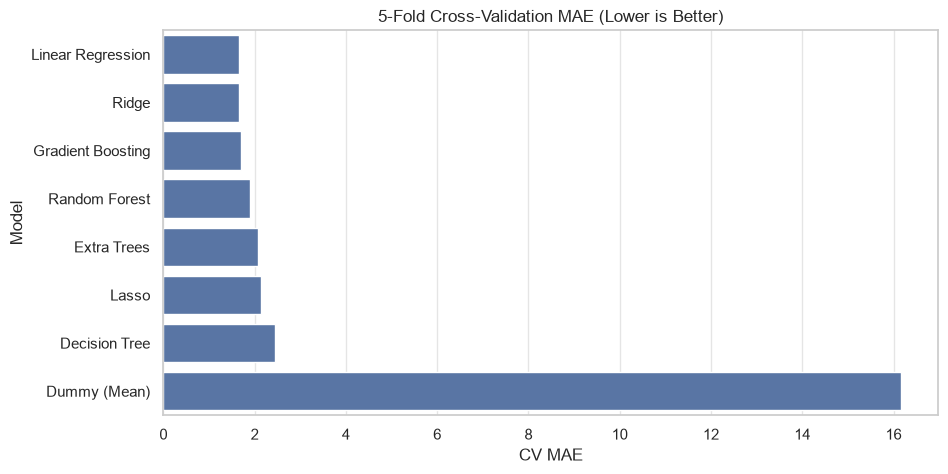

In [11]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x='CV MAE', y='Model')
plt.title('5-Fold Cross-Validation MAE (Lower is Better)')
plt.show()


In [12]:
best_model_name = results_df.iloc[0]['Model']
best_pipeline = pipelines[best_model_name]
y_pred = best_pipeline.predict(X_test)

test_metrics = pd.DataFrame([{
    'Model': best_model_name,
    'MAE': mean_absolute_error(y_test, y_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
    'R2': r2_score(y_test, y_pred)
}])
display(test_metrics)
print('Selected model:', best_model_name)


,Model,MAE,RMSE,R2
0,Linear Regression,1.654124,2.07695,0.988594


Selected model: Linear Regression


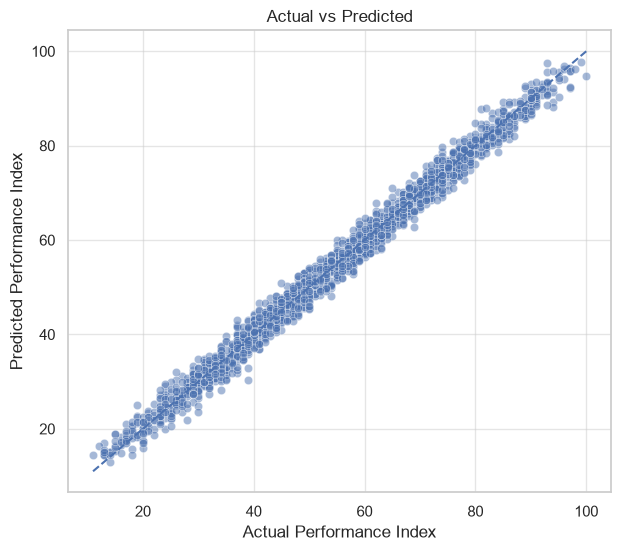

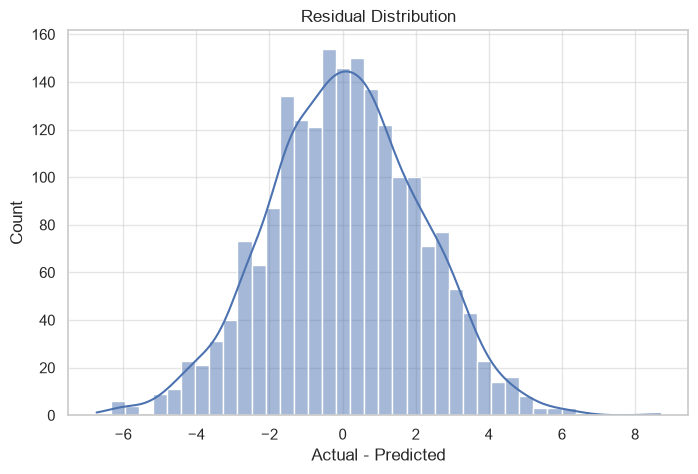

In [13]:
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=.5)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], linestyle='--')
plt.xlabel('Actual Performance Index')
plt.ylabel('Predicted Performance Index')
plt.title('Actual vs Predicted')
plt.show()

residuals = y_test - y_pred
plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=40, kde=True)
plt.title('Residual Distribution')
plt.xlabel('Actual - Predicted')
plt.show()


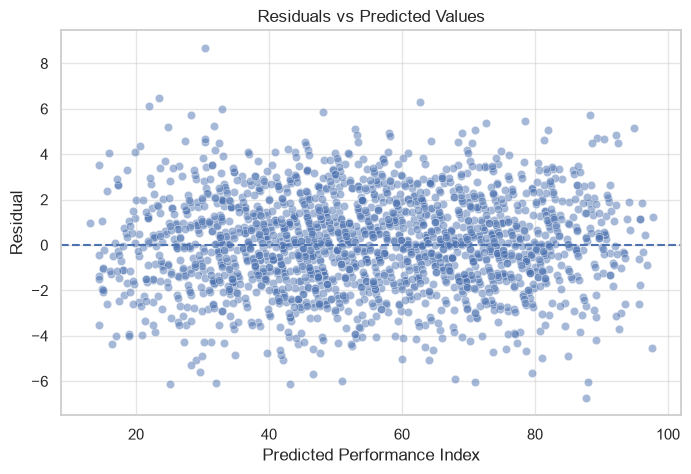

In [14]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuals, alpha=.5)
plt.axhline(0, linestyle='--')
plt.xlabel('Predicted Performance Index')
plt.ylabel('Residual')
plt.title('Residuals vs Predicted Values')
plt.show()


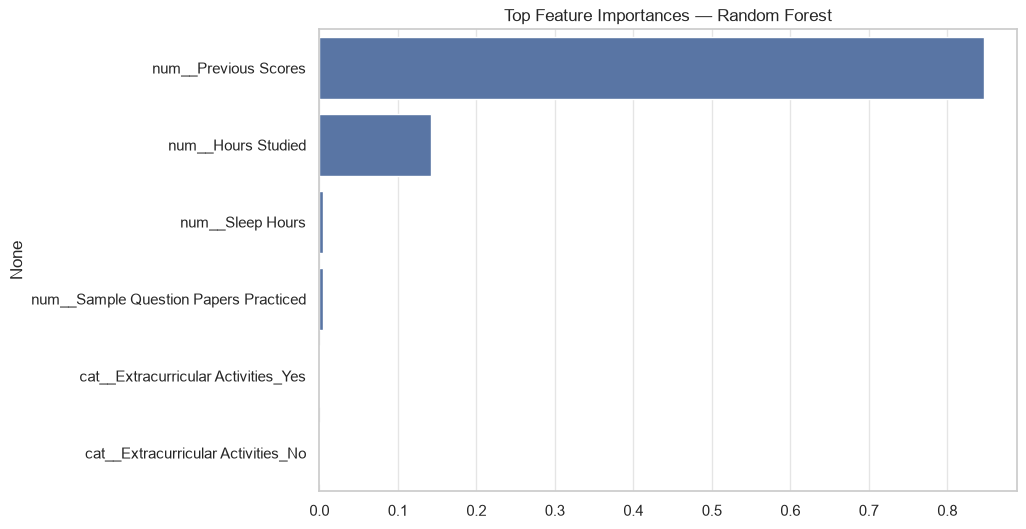

,Importance
num__Previous Scores,0.846316
num__Hours Studied,0.142661
num__Sleep Hours,0.004963
num__Sample Question Papers Practiced,0.004624
cat__Extracurricular Activities_Yes,0.000722
cat__Extracurricular Activities_No,0.000715


In [15]:
tree_model_names = ['Random Forest', 'Extra Trees', 'Gradient Boosting', 'Decision Tree']
importance_model_name = next((n for n in tree_model_names if n in pipelines), None)

if importance_model_name:
    pipe = pipelines[importance_model_name]
    model = pipe.named_steps['model']
    feature_names = pipe.named_steps['preprocessor'].get_feature_names_out()
    importances = pd.Series(model.feature_importances_, index=feature_names).sort_values(ascending=False)
    top_importances = importances.head(20)
    plt.figure(figsize=(9, 6))
    sns.barplot(x=top_importances.values, y=top_importances.index)
    plt.title(f'Top Feature Importances — {importance_model_name}')
    plt.show()
    display(top_importances.to_frame('Importance'))


In [16]:
display(pd.DataFrame({
    'Actual Performance Index': y_test.iloc[:20].values,
    'Predicted Performance Index': y_pred[:20]
}))


,Actual Performance Index,Predicted Performance Index
0,79,77.457752
1,75,76.477131
2,45,44.147212
3,91,91.330736
4,42,44.561779
5,39,35.942688
6,80,81.569376
7,57,58.968041
8,56,51.981680
9,62,62.429884
